# IT25101088 — Ariyasinghe P.A.D.A.J. — Underwater Color Correction (CLAHE)

**Dataset:** AQUA20 (taufiktrf/AQUA20 on Hugging Face) — 8,171 underwater images across 20 marine species,
captured under real-world conditions: reduced visibility, inconsistent lighting, and partial occlusion.


In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path('../..') / 'scripts'))
from data_utils import load_aqua20, get_class_names, to_numpy

import numpy as np
import matplotlib.pyplot as plt

dataset = load_aqua20()
class_names = get_class_names(dataset)
print('Train samples:', len(dataset['train']))
print('Test samples:', len(dataset['test']))
print('Number of classes:', len(class_names))

c:\Users\nesal\Downloads\Sliit\AIML\GROUP_ID\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train samples: 6559
Test samples: 1612
Number of classes: 20


In [2]:
import cv2

## Why this technique is needed for AQUA20
- Underwater images suffer from color cast (water absorbs red wavelengths first) and low contrast due to inconsistent, scattered lighting.
- Plain RGB decoding is not enough here — we apply CLAHE (Contrast Limited Adaptive Histogram Equalization) on the luminance channel to recover contrast and detail lost underwater.


In [3]:
def apply_clahe(image_array):
    lab = cv2.cvtColor(image_array, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_eq = clahe.apply(l)
    lab_eq = cv2.merge((l_eq, a, b))
    return cv2.cvtColor(lab_eq, cv2.COLOR_LAB2RGB)

example = to_numpy(dataset['train'][0]['image'], size=(224, 224))
corrected = apply_clahe(example)

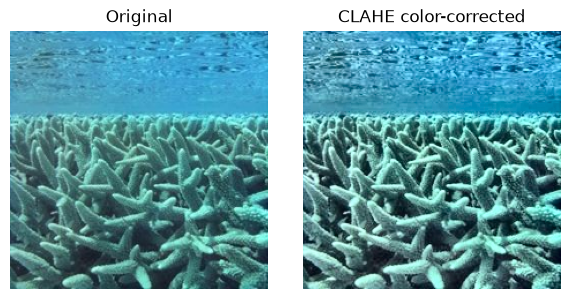

In [4]:
output_dir = Path('../..') / 'results' / 'eda_visualizations'
output_dir.mkdir(parents=True, exist_ok=True)
plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plt.imshow(example)
plt.title('Original')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(corrected)
plt.title('CLAHE color-corrected')
plt.axis('off')
plt.tight_layout()
plt.savefig(output_dir / 'color_correction_before_after.png', bbox_inches='tight')
plt.show()

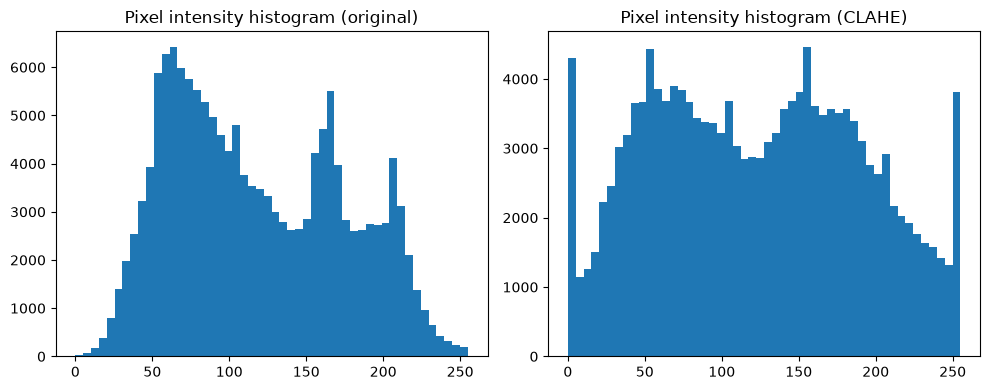

In [5]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(example.ravel(), bins=50)
plt.title('Pixel intensity histogram (original)')
plt.subplot(1, 2, 2)
plt.hist(corrected.ravel(), bins=50)
plt.title('Pixel intensity histogram (CLAHE)')
plt.tight_layout()
plt.savefig(output_dir / 'color_correction_histograms.png', bbox_inches='tight')
plt.show()

## Interpretation 
For the sample image, the pixel intensity standard deviation increases from about 55.9 (original) to about
67.8 after CLAHE (mean shifts only slightly, from ~118.1 to ~122.4), and the histogram visibly spreads out
from a narrow, compressed band into a wider range covering more of the 0-255 scale. This confirms CLAHE is
doing what it's meant to: it redistributes the luminance histogram locally (per 8x8 tile) so that dark,
low-contrast regions - typical of underwater shots where light scatters and attenuates with depth - gain
visible tonal separation instead of being clumped into a narrow gray band.

This should help a CNN distinguish species that look similar under the original poor-contrast conditions
because edges, textures, and color boundaries (e.g. the mottled skin pattern on a rayfish vs. the smoother
body of a shark, or the texture of coral vs. a sea anemone) become more separable once local contrast is
enhanced. Without this step, two visually similar low-contrast species could produce very similar raw pixel
statistics, making it harder for early convolutional filters to pick up the fine-grained cues needed to tell
them apart.